# 03 — Preprocessing du dataset pour l'apprentissage supervisé

**Objectif :** transformer la grille ERA5-Land masquée (sortie du notebook 01, analysée dans le notebook 02 — EDA) en un dataset tabulaire **prêt pour le supervised learning** : prédire la **classe de température à 2 m du mois M+1** (3 intervalles de même largeur) à partir des variables du mois M.

**Continuité avec l'EDA.** Ce notebook part du même fichier que l'EDA (`data/processed/era5_algeria_masked_2x2_v2.nc`) et ne refait pas l'analyse exploratoire. Il ne reprend que :
- la **conversion des unités** (indispensable pour que le notebook s'exécute seul, sans variables créées dans le notebook 02) ;
- certaines **statistiques recalculées après correction et sur le Train uniquement** (asymétrie, corrélations), parce que celles de l'EDA ont été calculées *avant* la correction de l'artefact 2022–2024 et *sur toute la période* (Test compris). Chaque recalcul est justifié à l'endroit où il apparaît.

Les constats de l'EDA qui motivent les traitements (valeurs citées du notebook 02) :

| Constat EDA (remarques de l'enseignante) | Ce que montre le notebook 02 | Traitement retenu ici |
|---|---|---|
| Valeurs manquantes à la frontière nord | 12 cellules de la grille brute dans le polygone sans aucune donnée ; **0 NaN** dans le domaine après réduction 2×2 (`coarsen().mean()` ignore les NaN) | Pas d'imputation : contrôle + exclusion des cellules hors domaine (§1) |
| Incohérences des moyennes mensuelles 2022–2024 | Variables **accumulées** (ssr, str, slhf, sshf, e, ro, tp) ≈ divisées par 2 pendant 18 mois ; t2m, d2m, sp, u10, v10 cohérents | **Known issue ERA5-Land** documenté par l'ECMWF (sept. 2022 → févr. 2024) → correction multiplicative (§2) |
| Distributions très asymétriques, beaucoup d'« outliers » | skew : ro 45.2, tp 5.8, slhf/e −4.2 ; 15–16 % d'outliers IQR pour slhf, e, ro, tp | Pas de suppression (extrêmes climatiques réels) ; contrôle physique (§3) ; **log signé** des variables très asymétriques (§7) |
| Faible variabilité | Variance Min-Max < 0.01 : slhf, ro, e, tp ; sp : 1 % de variance temporelle | ro supprimée (quasi constante + redondante) ; slhf, tp réévaluées après log ; sp conservée (proxy d'altitude) (§6–7) |
| Fortes corrélations (Spearman) | slhf–e = 1.000 ; ro–tp = 0.980 ; ssr–sshf = −0.948 | e supprimée (même grandeur physique) ; ro supprimée ; ssr et sshf conservées (§6) |

## Ordre du pipeline et justification

| # | Étape | Pourquoi à cet endroit |
|---|---|---|
| 1 | Complétude / intégrité de la grille | Toute étape suivante suppose une grille complète et un axe temporel continu (le décalage M+1 en dépend). |
| 2 | Correction de l'artefact ERA5-Land 2022–2024 | Erreur **de source** : elle fausse toutes les statistiques en aval (asymétrie, corrélations, quartiles, moyennes du scaler). Elle doit donc être corrigée en premier. Elle est **déterministe** (liste de mois documentée + facteur constant estimé sur des mois du Train) → aucune fuite. |
| 3 | Contrôles de cohérence physique, décision sur les outliers | Après correction, sinon les mois 2022–2024 apparaissent comme anormaux à tort. |
| 4 | Tableau échantillons + **cible M+1** | La cible se construit sur la grille complète et ordonnée, **avant** toute séparation, pour que chaque cellule garde sa continuité temporelle. |
| 5 | **Split chronologique** | Doit précéder toute étape qui *apprend* quelque chose des données (choix des features, seuils de discrétisation, scaler). |
| 6 | Sélection des features (redondance, faible variance) | Décidée sur le **Train** uniquement. |
| 7 | Transformation des distributions asymétriques | Après la sélection (inutile de transformer des variables supprimées), avant le scaling (le scaler doit voir les données transformées). |
| 8 | Feature extraction (encodage cyclique du mois) | Transformation sans paramètre, avant le scaling. |
| 9 | Discrétisation de la cible (equal-width, 3 classes) | Bornes calculées sur le **Train**, appliquées au Test. |
| 10 | Analyse des classes | Une fois les classes définies. |
| 11 | Feature scaling | Dernière transformation : ajusté sur le Train, appliqué au Test. |
| 12 | Export + vérifications | — |

## 0. Chargement et conversion des unités

In [55]:
from pathlib import Path
import json, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

DATA_FILE = Path("data") / "processed" / "era5_algeria_masked_2x2_v2.nc"
_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents] if (p / DATA_FILE).exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"{DATA_FILE} introuvable : exécutez d'abord le notebook 01.")
OUT_DIR = PROJECT_ROOT / "data" / "supervisedv2"
OUT_DIR.mkdir(parents=True, exist_ok=True)

ds = xr.open_dataset(PROJECT_ROOT / DATA_FILE).load()
print("Fichier :", PROJECT_ROOT / DATA_FILE)
print("Dimensions :", dict(ds.sizes))

Fichier : C:\Users\hp\Downloads\Climate_Data_Mining_Algeria\Climate_Data_Mining_Algeria\Climate_Data_Mining\data\processed\era5_algeria_masked_2x2_v2.nc
Dimensions : {'valid_time': 141, 'latitude': 95, 'longitude': 105}


In [56]:
# Variables imposées par le sujet (features supervisées) + t2m (qui sert uniquement à construire la cible)
FEATURES_SPEC = ["d2m", "slhf", "ssr", "str", "sshf", "ro", "e", "u10", "v10", "sp", "tp"]
BASE = ["t2m"] + FEATURES_SPEC
ACCUMULATED = ["slhf", "ssr", "str", "sshf", "ro", "e", "tp"]      # variables accumulées ERA5-Land (Table 3 de la doc)
UNITS = {"d2m": "°C", "t2m": "°C", "slhf": "W/m²", "ssr": "W/m²", "str": "W/m²", "sshf": "W/m²",
         "ro": "mm/j", "e": "mm/j", "tp": "mm/j", "u10": "m/s", "v10": "m/s", "sp": "hPa"}

# Même conversion que le notebook 02 (reprise nécessaire : le notebook doit être autonome)
conv = xr.Dataset(coords=ds.coords)
for v in ["d2m", "t2m"]:                 conv[v] = ds[v] - 273.15          # K -> °C
for v in ["slhf", "ssr", "str", "sshf"]: conv[v] = ds[v] / 86400.0         # J/m² par jour -> W/m²
for v in ["ro", "e", "tp"]:              conv[v] = ds[v] * 1000.0          # m par jour -> mm/j
conv["sp"] = ds["sp"] / 100.0                                             # Pa -> hPa
conv["u10"], conv["v10"] = ds["u10"], ds["v10"]
conv = conv[BASE]

TIMES = pd.DatetimeIndex(conv.valid_time.values)
print("Période :", TIMES.min().date(), "→", TIMES.max().date(), f"({len(TIMES)} mois)")

Période : 2015-01-01 → 2026-09-01 (141 mois)


## 1. Complétude de la grille — valeurs manquantes de la frontière nord

**Problème.** L'enseignante a relevé des valeurs manquantes sur quelques points de la frontière nord, selon la méthode d'intersection avec la carte. L'EDA a montré l'origine : sur la grille brute, **12 cellules** sont dans le polygone de l'Algérie mais n'ont **aucune** valeur sur toute la période. ERA5-Land est un produit *terre* : ces points sont masqués côté mer.

**Interprétation.** Dans le notebook 01, la réduction 2×2 utilise `coarsen().mean()`, qui ignore les NaN. Une cellule réduite n'est donc NaN que si ses 4 sous-cellules le sont. Les cellules de bord partiellement couvertes sont calculées à partir de 1 à 3 sous-cellules valides.

**Décision.** Aucune imputation.
- Une cellule sans aucune donnée n'est pas une valeur manquante à reconstituer : c'est un point **hors du domaine terrestre**. L'imputer (moyenne, médiane, kNN…) fabriquerait des valeurs « terrestres » là où il n'y a pas de terre. On l'**exclut** du domaine, comme dans l'EDA.
- Si une version du masque produisait des cellules avec des mois manquants isolés, la cellule ci-dessous applique une imputation par la **moyenne des cellules voisines au même mois** (imputation « intelligente » du cours 04, variante spatiale du kNN). On évite la moyenne globale : elle mélangerait le Sahara et la côte. Sur les données du notebook 02, ce cas ne se présente pas (0 cellule partielle).

In [57]:
valid_cells = conv["t2m"].notnull().any("valid_time")             # domaine = au moins une valeur
partial = (conv[BASE].to_array().isnull().any(("variable", "valid_time"))) & valid_cells
n_grid, n_dom = valid_cells.size, int(valid_cells.sum())
print(f"Cellules de la grille : {n_grid} | dans le domaine : {n_dom} | hors domaine (exclues) : {n_grid - n_dom}")
print("Cellules du domaine avec au moins un NaN :", int(partial.sum()))

def impute_spatial_neighbours(da, max_iter=5):
    # Remplace chaque NaN du domaine par la moyenne de ses 8 voisins au même pas de temps
    for _ in range(max_iter):
        hole = da.isnull() & valid_cells
        if not bool(hole.any()):
            break
        neigh = da.rolling(latitude=3, longitude=3, center=True, min_periods=1).mean()
        da = da.where(~hole, neigh)
    return da

if int(partial.sum()) > 0:
    for v in BASE:
        conv[v] = impute_spatial_neighbours(conv[v])
    left = int(conv[BASE].to_array().isnull().any("variable").where(valid_cells, False).sum())
    print("→ imputation spatiale appliquée ; NaN restants dans le domaine :", left)
else:
    print("→ aucune imputation nécessaire (conforme à l'EDA)")

# Intégrité de l'axe temporel (prérequis du décalage M+1)
assert (TIMES.to_period("M").to_series().diff().dropna().apply(lambda x: x.n) == 1).all(), "mois manquants"
assert TIMES.is_monotonic_increasing and TIMES.is_unique
print("Axe temporel : mensuel, continu, trié, sans doublon ✔")

Cellules de la grille : 9975 | dans le domaine : 5424 | hors domaine (exclues) : 4551
Cellules du domaine avec au moins un NaN : 0
→ aucune imputation nécessaire (conforme à l'EDA)
Axe temporel : mensuel, continu, trié, sans doublon ✔


## 2. Incohérences 2022–2024 : correction de l'artefact ERA5-Land

### 2.1 Diagnostic

**Observation (EDA, §3 et Q-Q plot 2022 vs 2024).** Sur la série régionale, ssr, str, slhf, sshf, e, ro et tp ont des moyennes mensuelles environ **deux fois plus faibles en valeur absolue** sur un bloc de mois entre fin 2022 et début 2024. Exemple : ssr en été ≈ 110 W/m² au lieu de ≈ 215. Les variables **instantanées** (t2m, d2m, sp, u10, v10) ne montrent pas ce saut.

**Pourquoi ce n'est pas un signal climatique.** Un rayonnement solaire net divisé par deux en plein été saharien, avec une température normale, est physiquement incohérent. Le saut touche **exactement** la famille des variables accumulées et aucune variable instantanée : c'est la signature d'une erreur de traitement.

**Source.** L'ECMWF a recensé ce problème comme *known issue* du produit *ERA5-Land monthly averaged reanalysis* : toutes les variables accumulées, **septembre 2022 → février 2024** (18 mois), données incorrectes sur les disques CDS et les bandes MARS. Les données corrigées ne sont disponibles qu'à partir de mars 2024, et les mois erronés n'ont pas été remplacés dans le produit mensuel.
Référence : *Issue affecting ERA5-Land monthly averaged reanalysis for the period September 2022 to February 2024*, forum ECMWF, 2024.

**Vérification sur nos données.** On compare la moyenne régionale de chaque mois (pondérée par cos(lat), comme dans l'EDA) à une **climatologie de référence** du même mois calendaire : la moyenne 2015–2021, des années propres, toutes dans le Train. Deux mesures :
- l'**anomalie standardisée** $z = (x - \bar{x}_{\text{mois}})/\sigma_{\text{mois}}$, calculable pour toutes les variables. Un mois normal reste dans ±3 ; l'artefact donne des |z| très élevés ;
- le **rapport** $x / \bar{x}_{\text{mois}}$, pour les variables accumulées seulement : ≈ 1 pour un mois normal, ≈ 0.5 pour un mois divisé par 2. Il n'a pas de sens pour d2m, u10 et v10, dont la moyenne est proche de 0 et change de signe.

In [58]:
AFFECTED = pd.date_range("2022-09-01", "2024-02-01", freq="MS")          # période documentée par l'ECMWF
REF_YEARS = (2015, 2021)                                                 # climatologie de référence (propre, Train)
w = np.cos(np.deg2rad(conv.latitude))

def regional(c):
    out = pd.DataFrame({v: c[v].weighted(w).mean(("latitude", "longitude")).to_series() for v in BASE})
    out.index = pd.to_datetime(out.index)
    return out

def _clim(reg):
    ref = reg[(reg.index.year >= REF_YEARS[0]) & (reg.index.year <= REF_YEARS[1])]
    g = ref.groupby(ref.index.month)
    return g.mean().loc[reg.index.month].values, g.std().loc[reg.index.month].values

def ratio_to_climatology(reg):
    return reg / _clim(reg)[0]

def zscore_to_climatology(reg):
    m, s = _clim(reg)
    return (reg - m) / s

reg_before = regional(conv)
ratio_before, z_before = ratio_to_climatology(reg_before), zscore_to_climatology(reg_before)
is_aff = ratio_before.index.isin(AFFECTED)

summary = pd.DataFrame({
    "|z| médian — mois documentés": z_before[is_aff].abs().median(),
    "|z| médian — autres mois": z_before[~is_aff].abs().median(),
    "rapport médian — mois documentés": ratio_before[is_aff].median().where(lambda s: s.index.isin(ACCUMULATED)),
    "rapport médian — autres mois": ratio_before[~is_aff].median().where(lambda s: s.index.isin(ACCUMULATED))}).round(3)
summary["accumulée ?"] = [v in ACCUMULATED for v in summary.index]
display(summary)

# Détection indépendante (contrôle) : mois où ssr ET str (variables accumulées les plus stables) sont < 75 % de la normale
flag = (ratio_before["ssr"] < 0.75) & (ratio_before["str"] < 0.75)
detected = ratio_before.index[flag]
print(f"Mois détectés dans les données : {len(detected)} ({detected.min():%Y-%m} → {detected.max():%Y-%m})" if len(detected) else "Aucun mois détecté")
print("Coïncide exactement avec la période documentée :", set(detected) == set(AFFECTED))

,|z| médian — mois documentés,|z| médian — autres mois,rapport médian — mois documentés,rapport médian — autres mois,accumulée ?
t2m,1.018,0.750,NaN,NaN,False
d2m,0.627,0.644,NaN,NaN,False
slhf,2.163,0.753,0.347,0.910,True
ssr,22.272,0.658,0.535,1.002,True
str,11.995,0.709,0.490,1.003,True
sshf,10.429,0.717,0.489,1.003,True
ro,1.217,0.739,0.145,0.691,True
e,2.163,0.753,0.347,0.910,True
u10,0.621,0.726,NaN,NaN,False
v10,0.993,0.798,NaN,NaN,False


Mois détectés dans les données : 18 (2022-09 → 2024-02)
Coïncide exactement avec la période documentée : True


### 2.2 Choix de la correction

Trois options possibles :

| Option | Avantage | Inconvénient |
|---|---|---|
| **Re-télécharger** les 18 mois via le produit « monthly averaged reanalysis by hour of day » (solution de contournement proposée par l'ECMWF) | Valeurs exactes | Nécessite de refaire l'extraction et le notebook 01 ; c'est la meilleure option si le temps le permet (voir limites) |
| Supprimer les 18 mois | Simple | Perd 13 % de la période ; casse la continuité temporelle nécessaire au M+1 (les mois d'août 2022 et de février 2024 perdraient leur cible) |
| Traiter comme manquant + imputer par la climatologie | Conserve les lignes | Efface la variabilité interannuelle réelle de ces mois (sécheresses, vagues de chaleur), alors que l'information est présente à un facteur près |
| **Correction multiplicative** | Conserve toutes les lignes **et** la variabilité réelle ; un facteur constant correspond à la nature de l'erreur (même facteur pour toutes les variables accumulées, aucune pour les instantanées) | Suppose un facteur constant : on le vérifie ci-dessous |

**Décision : correction multiplicative.** Le facteur est estimé uniquement sur les mois affectés qui appartiennent au **Train** (sept. 2022 → nov. 2023 : les features de décembre 2023 serviront à prédire janvier 2024, donc au Test, voir §5). La référence est la climatologie 2015–2021. Le facteur est d'abord estimé séparément pour chaque variable accumulée, pour vérifier qu'il est **commun**. La valeur appliquée est la médiane des facteurs de **ssr** et **str**, les deux variables accumulées dont la variabilité interannuelle est la plus faible (≈ ±5 %), donc les mieux adaptées à l'estimation. Si cette valeur est à moins de 0.1 de 2, on applique exactement **2** : c'est l'explication la plus simple d'une erreur de traitement (moitié de la valeur), et on évite d'ajuster du bruit.

In [59]:
est_months = AFFECTED[AFFECTED <= "2023-11-01"]                       # mois affectés appartenant au Train
inv = 1.0 / ratio_before.loc[est_months, ACCUMULATED]
factors = pd.DataFrame({"facteur médian": inv.median(), "écart interquartile": inv.quantile(.75) - inv.quantile(.25)}).round(3)
display(factors)

f_est = float(np.median([factors.loc["ssr", "facteur médian"], factors.loc["str", "facteur médian"]]))
FACTOR = 2.0 if abs(f_est - 2.0) < 0.1 else round(f_est, 3)
cv_month = float(inv[["ssr", "str"]].mean(axis=1).std() / inv[["ssr", "str"]].mean(axis=1).mean())
print(f"Facteur estimé (ssr, str) = {f_est:.3f} → facteur appliqué = {FACTOR}")
print(f"Stabilité d'un mois à l'autre (coefficient de variation ssr/str) : {100*cv_month:.1f} %")

,facteur médian,écart interquartile
slhf,3.085,1.583
ssr,1.864,0.049
str,2.043,0.058
sshf,2.044,0.084
ro,7.204,5.533
e,3.085,1.583
tp,3.806,3.385


Facteur estimé (ssr, str) = 1.954 → facteur appliqué = 2.0
Stabilité d'un mois à l'autre (coefficient de variation ssr/str) : 3.1 %


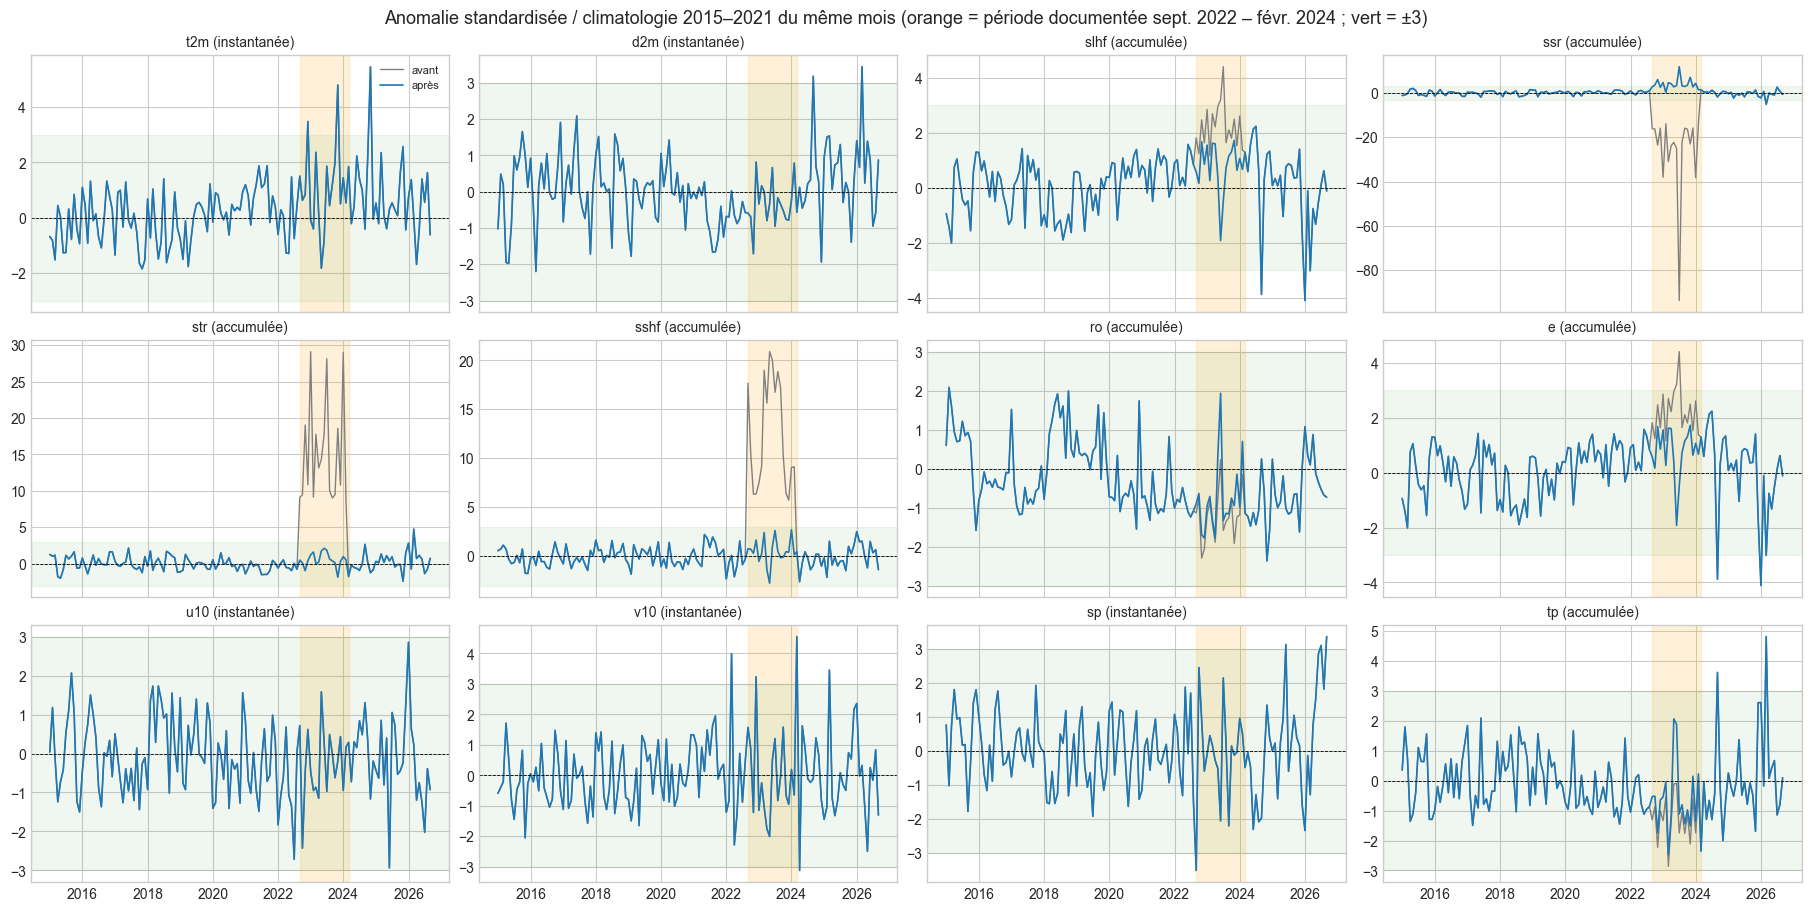

Sur les 18 mois corrigés, variables accumulées :


,slhf,ssr,str,sshf,ro,e,tp
rapport avant,0.347,0.535,0.490,0.489,0.145,0.347,0.264
rapport après,0.695,1.071,0.980,0.977,0.291,0.695,0.528
|z| médian avant,2.163,22.272,11.995,10.429,1.217,2.163,1.207
|z| médian après,0.961,3.384,0.589,0.627,0.972,0.961,1.045


In [63]:
gridc = conv.copy()
sel = gridc.valid_time.dt.strftime("%Y-%m").isin(AFFECTED.strftime("%Y-%m"))
for v in ACCUMULATED:
    gridc[v] = xr.where(sel, conv[v] * FACTOR, conv[v])
gridc = gridc.transpose("valid_time", "latitude", "longitude")
reg_after = regional(gridc)
ratio_after, z_after = ratio_to_climatology(reg_after), zscore_to_climatology(reg_after)

fig, axes = plt.subplots(3, 4, figsize=(18, 9), sharex=True, constrained_layout=True)
for ax, v in zip(axes.flat, BASE):
    ax.axvspan(AFFECTED.min(), AFFECTED.max() + pd.offsets.MonthEnd(1), color="orange", alpha=.15)
    ax.plot(z_before.index, z_before[v], color="grey", lw=1, label="avant")
    ax.plot(z_after.index, z_after[v], color="tab:blue", lw=1.2, label="après")
    ax.axhspan(-3, 3, color="green", alpha=.06); ax.axhline(0, color="k", lw=.6, ls="--")
    ax.set_title(f"{v} ({'accumulée' if v in ACCUMULATED else 'instantanée'})", fontsize=10)
axes.flat[0].legend(fontsize=8)
fig.suptitle("Anomalie standardisée / climatologie 2015–2021 du même mois (orange = période documentée sept. 2022 – févr. 2024 ; vert = ±3)", fontsize=13)
plt.show()

check = pd.DataFrame({"rapport avant": ratio_before[is_aff][ACCUMULATED].median(),
                      "rapport après": ratio_after[is_aff][ACCUMULATED].median(),
                      "|z| médian avant": z_before[is_aff][ACCUMULATED].abs().median(),
                      "|z| médian après": z_after[is_aff][ACCUMULATED].abs().median()}).round(3)
print("Sur les 18 mois corrigés, variables accumulées :"); display(check.T)

**Effet.** Après correction, les variables accumulées retrouvent sur les 18 mois un rapport proche de 1 et des anomalies dans la plage normale (±3), comme les autres années. Pour ro et tp, la dispersion reste plus forte : elle vient de leur variabilité naturelle (pluie), pas de la correction. Les variables instantanées n'ont pas été modifiées.

**Limite.** Le facteur constant reconstitue l'ordre de grandeur et la variabilité, pas les valeurs exactes. La solution idéale reste de re-télécharger les 18 mois via la solution de contournement de l'ECMWF.

## 3. Cohérence physique et décision sur les outliers

**Constat EDA.** slhf, e, ro et tp ont 15–16 % d'outliers selon la règle IQR et 2–3 % selon le Z-score. Les autres variables en ont environ 1 % ou moins.

**Pourquoi on ne supprime pas ces valeurs.**
1. Les causes d'outliers listées dans le cours 03 sont les erreurs de saisie, les erreurs de capteur et les **cas extrêmes naturels**. ERA5-Land est une réanalyse : un modèle physique contraint par des observations. Il n'y a ni saisie ni capteur défaillant au niveau de la cellule. Le seul défaut systématique du produit (§2) est déjà corrigé.
2. Ces « outliers » viennent de la **forme** de la distribution, pas d'erreurs. La pluie est nulle la plupart du temps sur le Sahara et forte quelques mois sur le Tell. La règle IQR et le Z-score supposent une distribution unimodale à peu près symétrique, ce qui n'est pas le cas ici : appliquées à une distribution à queue lourde, elles signalent mécaniquement la queue.
3. Supprimer ces lignes retirerait les mois pluvieux du nord, donc une région climatique entière, et biaiserait le modèle. Les tronquer (*capping*) écraserait l'information sur les événements forts.

Le cours 04 propose une autre option : l'**inspection combinée machine + humain**. On l'applique avec des **règles physiques** : on ne retire que ce qui est physiquement impossible. Les queues lourdes seront ensuite traitées par **transformation** (§7), autre option du cours 04.

In [ ]:
X = gridc[BASE].where(valid_cells)
rules = {
    "tp < 0 (précipitation négative)":            (X["tp"] < 0),
    "ro < 0 (ruissellement négatif)":             (X["ro"] < 0),
    "ssr < 0 (rayonnement solaire net négatif)":  (X["ssr"] < 0),
    "d2m > t2m + 0.05 (rosée > température)":     (X["d2m"] > X["t2m"] + 0.05),
    "sp hors [500, 1100] hPa":                    ((X["sp"] < 500) | (X["sp"] > 1100)),
    "|u10| ou |v10| > 40 m/s":                    ((abs(X["u10"]) > 40) | (abs(X["v10"]) > 40)),
}
phys = pd.Series({k: int(m.sum()) for k, m in rules.items()}, name="violations")
display(phys.to_frame())

# Seule correction prévue : les petites valeurs négatives numériques de tp/ro (arrondi de la réanalyse) sont mises à 0
for v in ["tp", "ro"]:
    n_neg = int((gridc[v] < 0).sum())
    gridc[v] = gridc[v].clip(min=0)
    if n_neg: print(f"{v} : {n_neg} valeurs négatives mises à 0")
print("Violations physiques restantes (hors tp/ro) :", int(phys.drop(phys.index[:2]).sum()))

,violations
tp < 0 (précipitation négative),0
ro < 0 (ruissellement négatif),0
ssr < 0 (rayonnement solaire net négatif),0
d2m > t2m + 0.05 (rosée > température),0
"sp hors [500, 1100] hPa",0
|u10| ou |v10| > 40 m/s,0


Violations physiques restantes (hors tp/ro) : 0


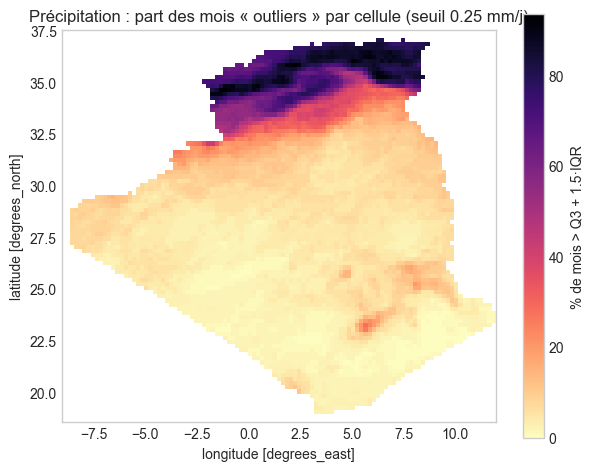

Part d'outliers IQR de tp : 15.1 % des échantillons, concentrés dans les cellules du nord (la carte montre une structure spatiale continue, pas des points isolés).


In [ ]:
# Les « outliers » de tp sont-ils des erreurs isolées ou une réalité climatique ? -> localisation spatiale
# (descriptif uniquement, sur les années du Train ; aucun paramètre n'est ajusté ici)
tr = gridc["tp"].sel(valid_time=slice("2015-01-01", "2023-12-01"))
vals = tr.values[:, valid_cells.values]
q1, q3 = np.nanpercentile(vals, [25, 75]); fence = q3 + 1.5 * (q3 - q1)
share = (tr > fence).mean("valid_time").where(valid_cells) * 100

fig, ax = plt.subplots(figsize=(7, 5.5))
share.plot.pcolormesh(ax=ax, x="longitude", y="latitude", cmap="magma_r", cbar_kwargs={"label": "% de mois > Q3 + 1.5·IQR"})
ax.set_aspect("equal"); ax.set_title(f"Précipitation : part des mois « outliers » par cellule (seuil {fence:.2f} mm/j)")
plt.show()
print(f"Part d'outliers IQR de tp : {float((vals > fence).mean())*100:.1f} % des échantillons, "
      f"concentrés dans les cellules du nord (la carte montre une structure spatiale continue, pas des points isolés).")

## 4. Tableau échantillons et intégration de la cible (température au mois M+1)

**Unité statistique :** une ligne = une **cellule** au mois **M** (même structure que l'EDA). Le sujet n'agrège pas spatialement : la grille a déjà été réduite d'un facteur 4 dans le notebook 01.

**Construction de la cible.** Pour chaque cellule, `t2m_next(M) = t2m(M+1)` de **la même cellule**. Le décalage se fait sur le tableau (temps × cellules) **avant** la mise à plat. Une cellule ne peut donc jamais recevoir la température d'une autre cellule, et le mois suivant est toujours le mois calendaire suivant (axe vérifié continu au §1). Le dernier mois (septembre 2026) n'a pas de mois suivant : ses lignes sont retirées. Ce n'est pas une imputation, la cible n'existe pas.

**t2m(M) n'est pas une feature :** le sujet fixe la liste des variables d'entrée, et t2m n'y figure pas. t2m sert uniquement à construire la cible.

In [ ]:
vm = valid_cells.values
T, N = len(TIMES), int(vm.sum())
ilat, ilon = np.where(vm)
grid = {v: gridc[v].values[:, vm] for v in BASE}                # chaque tableau : (T, N)

target = np.vstack([grid["t2m"][1:], np.full((1, N), np.nan)])  # t2m(M+1) de la même cellule

df = pd.DataFrame({v: grid[v].reshape(-1) for v in FEATURES_SPEC})
df.insert(0, "time", np.repeat(TIMES.values, N))
df.insert(1, "cell", np.tile(np.arange(N), T))
df.insert(2, "lat", np.tile(gridc.latitude.values[ilat], T))
df.insert(3, "lon", np.tile(gridc.longitude.values[ilon], T))
df["month"] = df["time"].dt.month
df["year"] = df["time"].dt.year
df["t2m_next"] = target.reshape(-1)
df["target_time"] = df["time"] + pd.offsets.MonthBegin(1)

n0 = len(df)
df = df.dropna(subset=["t2m_next"]).reset_index(drop=True)
print(f"{n0:,} lignes → {len(df):,} après retrait du dernier mois ({n0-len(df):,} lignes = {N:,} cellules × 1 mois)")

# Vérification indépendante sur 2000 lignes tirées au hasard : la cible = t2m de la même cellule, mois suivant
chk = df.sample(2000, random_state=1)
ref = gridc["t2m"].sel(latitude=xr.DataArray(chk["lat"].values), longitude=xr.DataArray(chk["lon"].values),
                      valid_time=xr.DataArray(chk["target_time"].values)).values
assert np.allclose(ref, chk["t2m_next"].values), "Erreur de construction de la cible M+1"
assert df.isna().sum().sum() == 0
print("Cible M+1 vérifiée (même cellule, mois suivant) ✔ — aucune valeur manquante ✔")

764,784 lignes → 759,360 après retrait du dernier mois (5,424 lignes = 5,424 cellules × 1 mois)
Cible M+1 vérifiée (même cellule, mois suivant) ✔ — aucune valeur manquante ✔


## 5. Séparation Train / Test chronologique

**Pourquoi chronologique.** Le sujet l'impose, et c'est indispensable pour un problème de prévision. Un découpage aléatoire placerait dans le Train des mois postérieurs aux mois du Test. Il mettrait aussi dans les deux ensembles des cellules voisines du même mois, qui sont très corrélées spatialement. Les scores seraient alors artificiellement élevés : c'est une fuite de données.

**Frontière définie sur le mois de la cible.**
- **Train :** mois cible de février 2015 à **décembre 2023** (features de janvier 2015 à novembre 2023) ;
- **Test :** mois cible de **janvier 2024** à septembre 2026 (features de décembre 2023 à août 2026).

Ce choix a deux conséquences :
1. **Aucune** température utilisée comme cible dans le Train n'est postérieure au début du Test, et aucune ligne n'est perdue à la frontière.
2. La coupure tombe sur une fin d'année : le Train contient **9 années complètes** de mois cibles (chaque mois calendaire y apparaît 9 fois, saisons équilibrées). Le Test couvre 2024, 2025 et janvier–septembre 2026.

On obtient environ 76 % / 24 %, proche du ratio usuel 80/20. On garde un Test assez long : il contient au moins deux cycles saisonniers complets, nécessaires pour évaluer les trois classes.

**Validation.** Pour régler les hyperparamètres dans la suite du projet, il faudra découper le Train lui-même chronologiquement (par ex. `TimeSeriesSplit`), sans jamais utiliser le Test.

In [ ]:
SPLIT_TARGET = pd.Timestamp("2024-01-01")
is_test = df["target_time"] >= SPLIT_TARGET
train, test = df[~is_test].copy(), df[is_test].copy()

split_info = pd.DataFrame({
    "lignes": [len(train), len(test)],
    "% lignes": [100 * len(train) / len(df), 100 * len(test) / len(df)],
    "mois features": [f"{train.time.min():%Y-%m} → {train.time.max():%Y-%m}", f"{test.time.min():%Y-%m} → {test.time.max():%Y-%m}"],
    "mois cibles": [f"{train.target_time.min():%Y-%m} → {train.target_time.max():%Y-%m}", f"{test.target_time.min():%Y-%m} → {test.target_time.max():%Y-%m}"],
    "nb mois": [train.time.nunique(), test.time.nunique()]}, index=["Train", "Test"]).round(1)
display(split_info)
assert train["target_time"].max() < test["target_time"].min() and train["time"].max() < test["time"].min()
assert set(train.cell) == set(test.cell)
print("Aucun chevauchement temporel entre Train et Test ✔")

,lignes,% lignes,mois features,mois cibles,nb mois
Train,580368,76.4,2015-01 → 2023-11,2015-02 → 2023-12,107
Test,178992,23.6,2023-12 → 2026-08,2024-01 → 2026-09,33


Aucun chevauchement temporel entre Train et Test ✔


## 6. Sélection des features : redondance et faible variabilité (décidée sur le Train)

**Pourquoi recalculer les corrélations.** Celles de l'EDA ont été calculées (i) **avant** la correction de 2022–2024 et (ii) **sur toute la période**. Or l'artefact divisait **simultanément** par 2 toutes les variables accumulées, ce qui gonfle mécaniquement leurs corrélations mutuelles. Les décisions doivent donc reposer sur les données corrigées du **Train**. Formule : **Spearman**, comme dans l'EDA (aucune variable normale au test de Shapiro ; relations monotones non linéaires ; robuste aux queues lourdes, cours 03).

**Critère du cours 04** (« What features to eliminate ») : corrélation > 0.9, variance < 0.01, variable non pertinente. On ne l'applique pas aveuglément. Une corrélation élevée peut venir uniquement du **cycle saisonnier commun** : deux variables physiquement distinctes qui suivent toutes deux les saisons. On calcule donc aussi la corrélation des **anomalies** : la valeur moins la climatologie de la cellule pour ce mois calendaire, estimée sur le Train. Deux variables vraiment redondantes restent corrélées une fois la saison retirée ; deux variables distinctes ne le restent pas.

In [ ]:
cand = FEATURES_SPEC
clim = train.groupby(["cell", "month"])[cand].transform("mean")          # climatologie Train (cellule × mois)
anom = train[cand] - clim

rho = train[cand].rank().corr()                                         # Spearman = Pearson sur les rangs
rho_anom = anom.rank().corr()
pairs = (rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack().rename("Spearman").to_frame()
         .join(rho_anom.stack().rename("Spearman anomalies")))
pairs.index.names = ["var 1", "var 2"]
top = pairs[pairs["Spearman"].abs() > 0.8].sort_values("Spearman", key=abs, ascending=False).round(3)
print("Paires avec |Spearman| > 0.8 sur le Train corrigé :"); display(top)

Paires avec |Spearman| > 0.8 sur le Train corrigé :


,,Spearman,Spearman anomalies
var 1,var 2,,
slhf,e,1.000,1.000
ro,tp,0.980,0.910
ssr,sshf,-0.948,-0.185


### 6.1 slhf et e : une seule grandeur physique

Le flux de chaleur latente **est** l'évaporation exprimée en énergie : $\text{slhf} = \rho_w L_v \, e$, avec $L_v \approx 2.5\times10^6$ J/kg. Avec nos unités, $\text{slhf [W/m²]} \approx 28.9 \times e \text{ [mm/j]}$. L'EDA trouve déjà ρ = 1.000. Les deux colonnes portent **exactement** la même information. Les garder toutes les deux revient à **doubler le poids** de l'évaporation dans les distances des KNN et SVM. → **suppression de `e`**, avec vérification numérique du rapport constant ci-dessous.

On garde **slhf** (W/m²) plutôt que e, par cohérence avec les autres termes du bilan d'énergie de surface (ssr, str, sshf), qui sont dans la même unité.

### 6.2 ro (ruissellement) : quasi constante et redondante avec tp

Les deux critères du cours sont réunis, et ils se renforcent :
- **faible variabilité** : dans l'EDA, la médiane et Q3 valent 0.000 mm/j (IQR = 0), 19 % de zéros exacts, variance 0.0014 (seul cas < 0.01 dans les unités d'analyse). Une feature nulle sur plus de 75 % des échantillons ne distingue presque aucune situation ;
- **redondance** : Spearman ro–tp = 0.98. Le ruissellement n'apparaît que là où il pleut, et il est d'abord une conséquence de la pluie ;
- **pertinence** : le ruissellement n'a pas de lien physique direct avec la température de l'air du mois suivant. Son effet indirect, via l'humidité du sol et l'évaporation, est déjà porté par tp et slhf.

Remarque honnête : le Pearson ro–tp ne vaut que 0.49 dans l'EDA. Le Spearman élevé est en partie dû aux nombreux ex-aequo autour de zéro (les deux variables sont nulles ensemble dans le désert). C'est pourquoi la décision repose sur la **combinaison** des trois arguments, et non sur la seule corrélation. → **suppression de `ro`**.

### 6.3 ssr et sshf : corrélées par la saison, mais physiquement distinctes → conservées

ρ ≈ −0.95, juste au-dessus du seuil 0.9. Ces deux variables ne mesurent pas la même chose : ssr est le rayonnement solaire **absorbé** ; sshf est le flux de chaleur **sensible**, qui dépend de l'écart de température entre le sol et l'air et de l'humidité du sol (partage entre chaleur sensible et latente). Leur corrélation brute vient surtout du cycle saisonnier commun. Si leur corrélation d'**anomalies** est nettement plus faible, sshf apporte une information propre. → **conservées** tant que |ρ anomalies| < 0.9, règle appliquée dans la cellule suivante.

De plus, le cours 04 précise que la redondance rend surtout les modèles de type *régression* instables. Les modèles prévus (KNN, SVM, Random Forest, ensembles) ne sont pas sensibles à une corrélation modérée entre deux variables.

### 6.4 sp : faible variabilité *temporelle*, mais variable spatiale utile → conservée

L'EDA montre que sp n'a que 1 % de variance temporelle. Sa variance totale est pourtant élevée (1124 hPa², variance Min-Max 0.018 > 0.01). La pression de surface est en effet presque entièrement déterminée par l'**altitude** de la cellule. sp fonctionne donc comme un proxy d'altitude, une information **spatiale** déterminante pour la température (≈ −6.5 °C/km). La « faible variabilité » signalée concerne le temps, pas l'espace : → **conservée**.

In [ ]:
DROP, REASONS = [], {}

# 6.1 slhf / e
ratio_le = (train["slhf"] / train["e"]).replace([np.inf, -np.inf], np.nan).dropna()
r_le = train[["slhf", "e"]].corr().iloc[0, 1]
print(f"slhf / e : rapport médian = {ratio_le.median():.2f} W/m² par mm/j (théorie ≈ 28.9), "
      f"écart interquartile = {ratio_le.quantile(.75)-ratio_le.quantile(.25):.3f} ; Pearson = {r_le:.4f}")
if r_le > 0.99:
    DROP.append("e"); REASONS["e"] = f"même grandeur que slhf (Pearson {r_le:.4f}, rapport constant)"

# 6.2 ro
share0 = float((train["ro"] < 0.01).mean())
rho_ro = float(rho.loc["ro", "tp"])
print(f"ro : {100*share0:.1f} % des échantillons < 0.01 mm/j ; IQR = {train['ro'].quantile(.75)-train['ro'].quantile(.25):.4f} ; "
      f"Spearman(ro, tp) = {rho_ro:.3f} ; Pearson(ro, tp) = {train[['ro','tp']].corr().iloc[0,1]:.3f}")
if share0 > 0.5:     # critère principal : quasi-constance ; la redondance avec tp renforce la décision
    DROP.append("ro"); REASONS["ro"] = f"quasi constante ({100*share0:.0f} % < 0.01 mm/j), information portée par tp (Spearman {rho_ro:.2f})"

# 6.3 ssr / sshf
r_raw, r_an = float(rho.loc["ssr", "sshf"]), float(rho_anom.loc["ssr", "sshf"])
print(f"ssr / sshf : Spearman brut = {r_raw:.3f} ; Spearman des anomalies = {r_an:.3f}")
if abs(r_an) > 0.9:
    DROP.append("sshf"); REASONS["sshf"] = f"redondante avec ssr même hors saison (ρ anomalies {r_an:.2f})"
else:
    print("  ↳ corrélation due au cycle saisonnier commun : ssr et sshf conservées")

FEATURES_KEPT = [v for v in FEATURES_SPEC if v not in DROP]
print("\nFeatures supprimées :", REASONS)
print("Features conservées :", FEATURES_KEPT)

slhf / e : rapport médian = 28.94 W/m² par mm/j (théorie ≈ 28.9), écart interquartile = 0.000 ; Pearson = 1.0000
ro : 95.8 % des échantillons < 0.01 mm/j ; IQR = 0.0004 ; Spearman(ro, tp) = 0.980 ; Pearson(ro, tp) = 0.495
ssr / sshf : Spearman brut = -0.948 ; Spearman des anomalies = -0.185
  ↳ corrélation due au cycle saisonnier commun : ssr et sshf conservées

Features supprimées : {'e': 'même grandeur que slhf (Pearson 1.0000, rapport constant)', 'ro': 'quasi constante (96 % < 0.01 mm/j), information portée par tp (Spearman 0.98)'}
Features conservées : ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'u10', 'v10', 'sp', 'tp']


## 7. Transformation des distributions très asymétriques

**Problème.** slhf (skew −4.2) et tp (5.8) ont des queues très lourdes, et la plupart des valeurs sont tassées près de zéro. Pour un modèle à **distance** (KNN, SVM-RBF), cela pose deux difficultés après mise à l'échelle :
- quelques valeurs extrêmes occupent presque toute l'étendue de la variable ;
- 90 % des échantillons ne diffèrent plus que de quelques centièmes.

C'est exactement la « faible variabilité Min-Max » relevée dans l'EDA (variance Min-Max < 0.01 pour slhf et tp). Elle ne vient pas d'une variable pauvre en information : elle vient d'une échelle dominée par la queue.

**Méthode (cours 04 « Handling outliers : transforming the data » et cours 05 « Mathematical functions »).** On applique un **logarithme signé** $x' = \operatorname{sign}(x)\,\ln(1 + |x|)$ :
- il est défini pour 0 (tp nul) et pour des valeurs négatives (slhf est négatif par convention ECMWF : flux vers le haut), alors que `log(x)` ne l'est pas ;
- il est **monotone** : l'ordre des valeurs, donc l'ordre de la pluie ou de l'évaporation, est conservé ;
- il est **sans paramètre** : rien n'est appris sur les données, donc aucune fuite possible ;
- il comprime la queue sans supprimer les extrêmes, ce qui complète la décision du §3.

**Règle de sélection.** On transforme une feature si (i) son asymétrie **sur le Train** dépasse 1 en valeur absolue (seuil usuel de « forte asymétrie », Bulmer 1979 ; ce seuil n'est pas donné dans le cours) **et** (ii) le log signé **réduit effectivement** cette asymétrie. La condition (ii) écarte les variables dont l'asymétrie ne vient pas d'une queue près de zéro. Exemple : sp (≈ 950 hPa), dont l'asymétrie vient de la répartition des altitudes ; un log ne changerait presque rien à sa forme. On ne transforme pas les variables modérément asymétriques : leur échelle est déjà correcte, et chaque transformation rend le modèle un peu moins lisible.

,skew Train,skew si log signé,transformée ?,variance Min-Max avant,variance Min-Max après
d2m,0.25,-0.29,False,0.0149,NaN
slhf,-4.17,-1.47,True,0.0043,0.0313
ssr,-0.11,-0.60,False,0.0293,NaN
str,0.33,0.83,False,0.0285,NaN
sshf,-0.39,2.75,False,0.0097,NaN
u10,0.09,0.59,False,0.0127,NaN
v10,-0.22,0.28,False,0.0163,NaN
sp,-0.84,-0.94,False,0.0182,NaN
tp,5.95,3.39,True,0.0020,0.0102


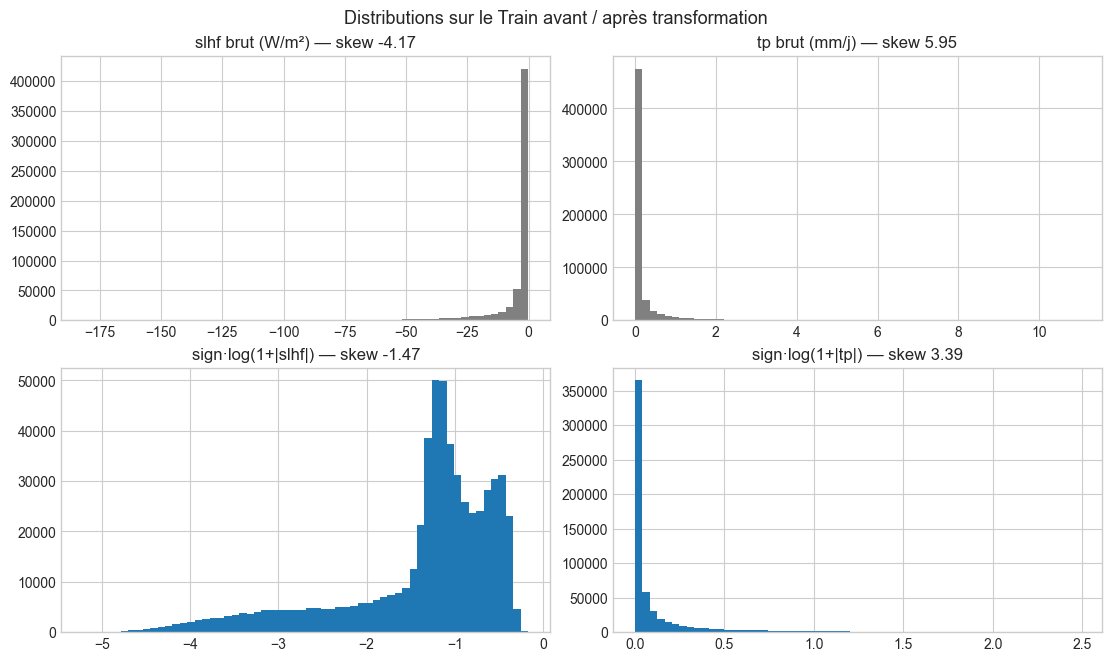

Variables transformées : ['slhf', 'tp']


In [ ]:
slog = lambda x: np.sign(x) * np.log1p(np.abs(x))
sk = train[FEATURES_KEPT].apply(lambda s: stats.skew(s))
sk_log = train[FEATURES_KEPT].apply(lambda s: stats.skew(slog(s)))
TRANSFORM = [v for v in FEATURES_KEPT if abs(sk[v]) > 1 and abs(sk_log[v]) < abs(sk[v])]

mm_var = lambda s: float(((s - s.min()) / (s.max() - s.min())).var())
tab = pd.DataFrame({"skew Train": sk.round(2), "skew si log signé": sk_log.round(2),
                    "transformée ?": [v in TRANSFORM for v in sk.index]})
tab["variance Min-Max avant"] = [mm_var(train[v]) for v in sk.index]
tab["variance Min-Max après"] = [mm_var(slog(train[v])) if v in TRANSFORM else np.nan for v in sk.index]
display(tab.round(4))

fig, axes = plt.subplots(2, max(len(TRANSFORM), 1), figsize=(5.5 * max(len(TRANSFORM), 1), 6.5), squeeze=False, constrained_layout=True)
for j, v in enumerate(TRANSFORM):
    axes[0, j].hist(train[v], bins=60, color="grey"); axes[0, j].set_title(f"{v} brut ({UNITS[v]}) — skew {sk[v]:.2f}")
    axes[1, j].hist(slog(train[v]), bins=60, color="tab:blue"); axes[1, j].set_title(f"sign·log(1+|{v}|) — skew {stats.skew(slog(train[v])):.2f}")
fig.suptitle("Distributions sur le Train avant / après transformation", fontsize=13); plt.show()

for part in (train, test):                       # transformation sans paramètre : même formule pour les deux ensembles
    for v in TRANSFORM:
        part[v] = slog(part[v])
print("Variables transformées :", TRANSFORM)

**Effet.** Pour les variables transformées, l'asymétrie diminue fortement et la variance Min-Max augmente nettement. La « faible variabilité » relevée dans l'EDA était donc en grande partie un effet d'échelle, et la transformation la corrige sans rien supprimer. Si une variable reste sous le seuil de 0.01 après transformation, on la garde quand même. D'une part, l'EDA a montré que ce seuil dépend des unités. D'autre part, la précipitation et l'évaporation renseignent sur l'humidité du sol et la nébulosité, qui modulent directement la température des semaines suivantes.

**Limite.** Le log dépend des unités (mm/j, W/m²) : c'est la raison pour laquelle on garde les unités physiques de l'EDA. Pour la Random Forest, la transformation est sans effet (les arbres ne dépendent que de l'ordre des valeurs). Elle ne nuit pas non plus.

## 8. Feature extraction : encodage cyclique du mois

**Problème.** Le sujet impose le mois comme feature. Codé de 1 à 12, il place décembre (12) et janvier (1) à la distance maximale, alors que ce sont deux mois d'hiver consécutifs. Pour un KNN ou un SVM, cette discontinuité artificielle déforme les voisinages, précisément sur la variable qui porte le cycle saisonnier, le principal moteur de la température du mois suivant.

**Méthode (cours 05 : fonctions trigonométriques).** On remplace le mois par ses coordonnées sur le cercle : $\text{month\_sin} = \sin(2\pi m/12)$, $\text{month\_cos} = \cos(2\pi m/12)$. Décembre et janvier deviennent voisins, et l'écart entre deux mois est proportionnel à leur distance dans le calendrier. Transformation sans paramètre → aucune fuite.

**Ce qu'on n'ajoute pas, et pourquoi** (« ne pas multiplier les traitements ») :
- *vitesse du vent* $\sqrt{u^2+v^2}$ (créée dans l'EDA) : son effet sur la température passe par les flux turbulents, déjà présents (sshf, slhf) ;
- *t2m(M)* (persistance) : ce serait sans doute la feature la plus prédictive, mais le sujet fixe la liste des features et ne l'inclut pas (voir limites) ;
- *latitude / longitude* : hors liste du sujet ; l'information spatiale principale (altitude) est déjà portée par sp. Elles sont exportées comme **métadonnées** pour pouvoir les ajouter plus tard si besoin.

**Année.** Conservée comme l'impose le sujet. Elle peut capter une tendance de long terme. Avec un split chronologique, les années du Test (2023–2026) sont au-delà de celles du Train : le modèle **extrapole** sur cette feature. C'est une limite à garder en tête dans l'interprétation des résultats.

In [ ]:
for part in (train, test):
    part["month_sin"] = np.sin(2 * np.pi * part["month"] / 12)
    part["month_cos"] = np.cos(2 * np.pi * part["month"] / 12)

FEATURES_FINAL = FEATURES_KEPT + ["month_sin", "month_cos", "year"]
print(f"{len(FEATURES_FINAL)} features finales :", FEATURES_FINAL)
display(train.drop_duplicates("month").sort_values("month")[["month", "month_sin", "month_cos"]].round(3).T)

12 features finales : ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'u10', 'v10', 'sp', 'tp', 'month_sin', 'month_cos', 'year']


,0,5424,10848,16272,21696,27120,32544,37968,43392,48816,54240,59664
month,1.000,2.000,3.0,4.000,5.000,6.0,7.000,8.000,9.0,10.000,11.000,12.0
month_sin,0.500,0.866,1.0,0.866,0.500,0.0,-0.500,-0.866,-1.0,-0.866,-0.500,-0.0
month_cos,0.866,0.500,0.0,-0.500,-0.866,-1.0,-0.866,-0.500,-0.0,0.500,0.866,1.0


## 9. Discrétisation de la cible : 3 intervalles de même largeur

**Méthode imposée** par le sujet : *equal-width partitioning* (cours 04), avec $W = (B - A)/3$, où $A$ et $B$ sont le minimum et le maximum de t2m(M+1).

**Ajusté sur le Train uniquement.** A et B sont calculés sur les cibles du Train, puis les **mêmes** bornes sont appliquées au Test. Les calculer sur toute la période ferait dépendre la définition des classes des températures du Test. Une valeur du Test hors de $[A, B]$ est rangée dans la classe extrême correspondante (intervalles extérieurs ouverts).

**Différence avec l'EDA.** L'EDA avait calculé des bornes exploratoires sur toute la période ([0.91, 14.33, 27.74, 41.16] °C). Les bornes ci-dessous peuvent légèrement différer : c'est voulu.

**Classes :** 0 = Froid, 1 = Modéré, 2 = Chaud (variable ordinale ; encodage entier ordonné, cours 05).

In [ ]:
A, B = float(train["t2m_next"].min()), float(train["t2m_next"].max())
W = (B - A) / 3
EDGES = [A, A + W, A + 2 * W, B]
LABELS = ["Froid", "Modéré", "Chaud"]
bins = [-np.inf, EDGES[1], EDGES[2], np.inf]

for part in (train, test):
    part["target_class"] = pd.cut(part["t2m_next"], bins=bins, labels=[0, 1, 2], right=True).astype(int)
    part["target_label"] = part["target_class"].map(dict(enumerate(LABELS)))

print(f"A = {A:.2f} °C, B = {B:.2f} °C, largeur W = {W:.2f} °C")
print("Bornes :", " | ".join(f"{LABELS[i]} ]{EDGES[i]:.2f}, {EDGES[i+1]:.2f}]" for i in range(3)))
out_lo, out_hi = int((test["t2m_next"] < A).sum()), int((test["t2m_next"] > B).sum())
print(f"Test hors de [A, B] : {out_lo} sous A, {out_hi} au-dessus de B ({100*(out_lo+out_hi)/len(test):.3f} % du Test)")

A = 0.91 °C, B = 41.16 °C, largeur W = 13.41 °C
Bornes : Froid ]0.91, 14.33] | Modéré ]14.33, 27.74] | Chaud ]27.74, 41.16]
Test hors de [A, B] : 0 sous A, 0 au-dessus de B (0.000 % du Test)


## 10. Analyse des effectifs et pourcentages des classes

,Train (n),Train (%),Test (n),Test (%)
target_label,,,,
Froid,102139,17.60,27308,15.26
Modéré,251697,43.37,75632,42.25
Chaud,226532,39.03,76052,42.49
Total,580368,100.00,178992,100.00


Rapport classe majoritaire / minoritaire (Train) : 2.46


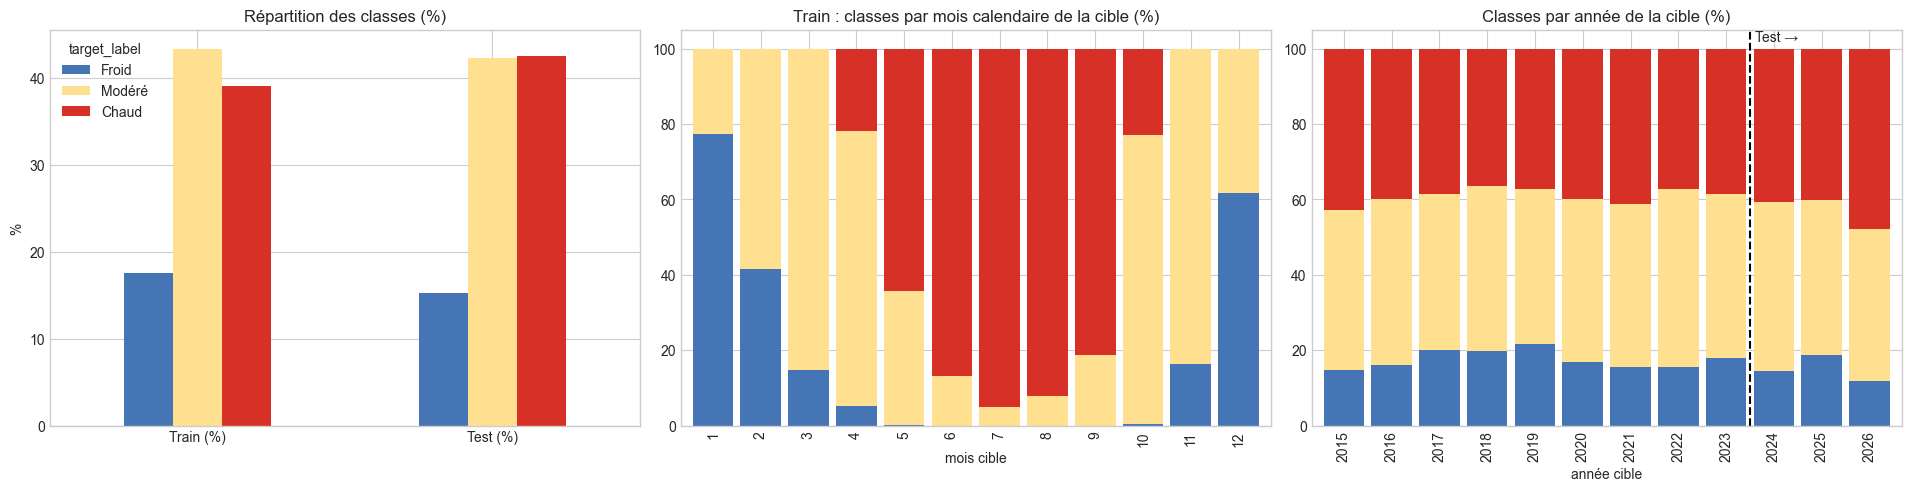

In [ ]:
dist = pd.DataFrame({
    "Train (n)": train["target_label"].value_counts().reindex(LABELS),
    "Train (%)": (train["target_label"].value_counts(normalize=True) * 100).reindex(LABELS),
    "Test (n)": test["target_label"].value_counts().reindex(LABELS),
    "Test (%)": (test["target_label"].value_counts(normalize=True) * 100).reindex(LABELS)}).round(2)
dist.loc["Total"] = [len(train), 100.0, len(test), 100.0]
dist[["Train (n)", "Test (n)"]] = dist[["Train (n)", "Test (n)"]].astype(int)
display(dist)
imb = dist.loc[LABELS, "Train (%)"].max() / dist.loc[LABELS, "Train (%)"].min()
print(f"Rapport classe majoritaire / minoritaire (Train) : {imb:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), constrained_layout=True)
colors = {"Froid": "#4575b4", "Modéré": "#fee090", "Chaud": "#d73027"}
dist.loc[LABELS, ["Train (%)", "Test (%)"]].T.plot.bar(ax=axes[0], color=[colors[l] for l in LABELS], rot=0)
axes[0].set_title("Répartition des classes (%)"); axes[0].set_ylabel("%")
pm = pd.crosstab(train["target_time"].dt.month, train["target_label"], normalize="index")[LABELS] * 100
pm.plot.bar(stacked=True, ax=axes[1], color=[colors[l] for l in LABELS], width=.85, legend=False)
axes[1].set_title("Train : classes par mois calendaire de la cible (%)"); axes[1].set_xlabel("mois cible")
both = pd.concat([train, test])
py = pd.crosstab(both["target_time"].dt.year, both["target_label"], normalize="index")[LABELS] * 100
py.plot.bar(stacked=True, ax=axes[2], color=[colors[l] for l in LABELS], width=.85, legend=False)
axes[2].axvline(py.index.get_loc(2024) - .5, color="k", lw=1.5, ls="--"); axes[2].text(py.index.get_loc(2024) - .4, 102, "Test →")
axes[2].set_title("Classes par année de la cible (%)"); axes[2].set_xlabel("année cible")
plt.show()

**Lecture.**
- **Déséquilibre attendu.** Avec des intervalles de même largeur, les classes n'ont pas le même effectif : leurs bornes suivent l'échelle de température, pas la fréquence des valeurs. C'est l'inconvénient du découpage *equal-width* signalé dans le cours 04 (données asymétriques mal gérées). La classe « Froid » est la minoritaire. Elle regroupe les mois d'hiver des Hauts Plateaux et de l'Atlas, et le Sahara n'y entre presque jamais.
- **La classe dépend fortement de la saison** (graphique du milieu). Le mois est donc une feature essentielle, ce qui justifie son encodage cyclique (§8).
- **Train et Test** peuvent avoir des proportions différentes. Le Test ne compte que 2,75 années, et ses années (2024–2026) ne sont pas forcément représentatives (années chaudes, été 2026 inclus mais pas l'hiver 2026–27). Cette différence est un effet réel de la chronologie, pas un défaut du découpage.

**Ce qu'on ne fait pas ici.** On ne rééquilibre pas les classes : sur-échantillonnage ou sous-échantillonnage sont des choix de **modélisation**, à faire **sur le Train uniquement** au moment de l'entraînement. Le Test doit garder sa distribution réelle. Pour la suite, on recommande des métriques robustes au déséquilibre (F1 macro, matrice de confusion) et, si nécessaire, `class_weight="balanced"` pour SVM et Random Forest.

## 11. Feature scaling

**Pourquoi.** KNN et SVM reposent sur des distances ou des produits scalaires. Sans mise à l'échelle, sp (≈ 950 hPa, écart-type ≈ 33) écraserait month_cos (écart-type ≈ 0.7) dans le calcul des distances (cours 05, remarque du cours 06 sur le KNN).

**Méthode : standardisation** (moyenne 0, écart-type 1), plutôt que :
- **Min-Max** : sensible aux extrêmes (cours 05). Les extrêmes climatiques ont été conservés (§3) et dominent encore un peu l'étendue de certaines variables ;
- **Robust scaler** : il n'est pas détaillé dans le cours (« TODO »). Après le log signé, les distributions restantes ne justifient plus un changement de méthode.

La standardisation donne à chaque feature le même poids en distance et une échelle adaptée au noyau RBF du SVM.

**Sans fuite.** Le scaler est **ajusté sur le Train** (`fit`), puis appliqué tel quel au Test (`transform`). Le Test n'a donc pas exactement une moyenne de 0 et un écart-type de 1, et c'est normal : un écart notable signale simplement un changement de distribution entre périodes (par ex. `year`, par construction).

In [ ]:
scaler = StandardScaler().fit(train[FEATURES_FINAL])
train_s, test_s = train.copy(), test.copy()
train_s[FEATURES_FINAL] = scaler.transform(train[FEATURES_FINAL])
test_s[FEATURES_FINAL] = scaler.transform(test[FEATURES_FINAL])

sc = pd.DataFrame({"moyenne Train (fit)": scaler.mean_, "écart-type Train (fit)": scaler.scale_,
                   "moyenne Train après": train_s[FEATURES_FINAL].mean().values,
                   "std Train après": train_s[FEATURES_FINAL].std(ddof=0).values,
                   "moyenne Test après": test_s[FEATURES_FINAL].mean().values,
                   "std Test après": test_s[FEATURES_FINAL].std(ddof=0).values}, index=FEATURES_FINAL)
display(sc.round(3))
assert np.allclose(train_s[FEATURES_FINAL].mean(), 0, atol=1e-6) and np.allclose(train_s[FEATURES_FINAL].std(ddof=0), 1, atol=1e-6)
print("Train standardisé (moyenne 0, écart-type 1) ✔ — Test transformé avec les paramètres du Train ✔")

,moyenne Train (fit),écart-type Train (fit),moyenne Train après,std Train après,moyenne Test après,std Test après
d2m,1.390,4.822,0.0,1.0,0.096,0.994
slhf,-1.370,0.891,-0.0,1.0,-0.038,1.020
ssr,167.048,42.558,0.0,1.0,-0.015,0.996
str,-117.172,22.555,-0.0,1.0,0.011,1.015
sshf,-41.393,21.762,0.0,1.0,-0.021,1.047
u10,-1.033,1.600,0.0,1.0,0.036,0.968
v10,-0.513,1.042,-0.0,1.0,0.003,1.017
sp,951.763,33.526,-0.0,1.0,-0.001,1.000
tp,0.120,0.251,0.0,1.0,0.042,1.057
month_sin,-0.000,0.710,-0.0,1.0,0.101,0.975


Train standardisé (moyenne 0, écart-type 1) ✔ — Test transformé avec les paramètres du Train ✔


## 12. Export du dataset pour le supervised learning

Fichiers écrits dans `data/supervised/` :

| Fichier | Contenu |
|---|---|
| `supervised_train.csv`, `supervised_test.csv` | métadonnées (`time`, `target_time`, `cell`, `lat`, `lon`) · **features standardisées** · `target_class` (0/1/2) · `target_label` · `t2m_next_C` (valeur continue, **pour référence uniquement, ne pas utiliser comme feature**) |
| `preprocessing_params.json` | tout ce qui a été appris ou décidé : facteur de correction et mois corrigés, features supprimées et raisons, variables transformées, bornes des classes, moyenne et écart-type du scaler, liste ordonnée des features |

Pour les modèles : `X = df[params["feature_columns"]]`, `y = df["target_class"]`. Les valeurs non standardisées s'obtiennent par `x = z · scale + mean`, avec les paramètres du JSON. La Random Forest peut utiliser indifféremment les features standardisées ou non : les arbres ne dépendent que de l'ordre des valeurs.

In [ ]:
META = ["time", "target_time", "cell", "lat", "lon"]
TARGETS = ["target_class", "target_label", "t2m_next_C"]
def export(part, name):
    out = part.rename(columns={"t2m_next": "t2m_next_C"})[META + FEATURES_FINAL + TARGETS]
    out.to_csv(OUT_DIR / name, index=False, float_format="%.6g", date_format="%Y-%m-%d")
    return out
exp_train, exp_test = export(train_s, "supervised_train.csv"), export(test_s, "supervised_test.csv")

params = {
    "source_file": str(DATA_FILE),
    "era5land_known_issue": {"months_corrected": [d.strftime("%Y-%m") for d in AFFECTED],
                             "variables": ACCUMULATED, "factor": FACTOR, "factor_estimated_ssr_str": round(f_est, 4),
                             "estimation_months": [d.strftime("%Y-%m") for d in est_months],
                             "reference_climatology_years": list(REF_YEARS)},
    "physical_clipping": "tp, ro clipped at 0",
    "split": {"rule": "target month < 2024-01 -> train ; >= 2024-01 -> test",
              "train_rows": len(train), "test_rows": len(test)},
    "dropped_features": REASONS,
    "signed_log_transformed": TRANSFORM,
    "feature_columns": FEATURES_FINAL,
    "target": {"column": "target_class", "labels": dict(enumerate(LABELS)), "method": "equal-width, 3 bins, fitted on train",
               "edges_C": [float(e) for e in EDGES], "outer_bins_open": True},
    "scaler": {"type": "StandardScaler (fit on train)", "mean": dict(zip(FEATURES_FINAL, scaler.mean_.round(6).tolist())),
               "scale": dict(zip(FEATURES_FINAL, scaler.scale_.round(6).tolist()))},
    "class_distribution_pct": {"train": dist.loc[LABELS, "Train (%)"].to_dict(), "test": dist.loc[LABELS, "Test (%)"].to_dict()},
}
with open(OUT_DIR / "preprocessing_params.json", "w", encoding="utf-8") as fh:
    json.dump(params, fh, ensure_ascii=False, indent=2)
for f in ["supervised_train.csv", "supervised_test.csv", "preprocessing_params.json"]:
    print(f"{f:28s} {(OUT_DIR/f).stat().st_size/1e6:8.1f} Mo")

supervised_train.csv             96.5 Mo
supervised_test.csv              29.6 Mo
preprocessing_params.json         0.0 Mo


## 13. Vérifications finales (relecture des fichiers exportés)

In [ ]:
P = json.load(open(OUT_DIR / "preprocessing_params.json", encoding="utf-8"))
tr = pd.read_csv(OUT_DIR / "supervised_train.csv", parse_dates=["time", "target_time"])
te = pd.read_csv(OUT_DIR / "supervised_test.csv", parse_dates=["time", "target_time"])
F = P["feature_columns"]
checks = {
    "colonnes identiques Train/Test": list(tr.columns) == list(te.columns),
    "aucune valeur manquante": int(tr.isna().sum().sum() + te.isna().sum().sum()) == 0,
    "nb de lignes = cellules × mois": len(tr) == N * tr.time.nunique() and len(te) == N * te.time.nunique(),
    "pas de doublon (cellule, mois)": not tr.duplicated(["cell", "time"]).any() and not te.duplicated(["cell", "time"]).any(),
    "cible = mois suivant": bool(((tr.target_time - tr.time).dt.days.between(28, 31)).all() and ((te.target_time - te.time).dt.days.between(28, 31)).all()),
    "Train strictement antérieur au Test": tr.target_time.max() < te.target_time.min(),
    "aucune feature interdite (t2m, cible, lat/lon, supprimées)": set(F).isdisjoint({"t2m", "t2m_next_C", "target_class", "target_label", "lat", "lon", *P["dropped_features"]}),
    "scaler ajusté sur le Train": np.allclose(tr[F].mean(), 0, atol=1e-3) and np.allclose(tr[F].std(ddof=0), 1, atol=1e-3),
    "bornes = equal-width du Train": np.isclose(tr.t2m_next_C.min(), P["target"]["edges_C"][0], atol=1e-3)
                                      and np.isclose(tr.t2m_next_C.max(), P["target"]["edges_C"][3], atol=1e-3)
                                      and np.allclose(np.diff(P["target"]["edges_C"]), np.diff(P["target"]["edges_C"])[0], atol=1e-3),
    # (tolérance 1e-3 °C : le CSV arrondit t2m_next_C à 6 chiffres significatifs, les valeurs pile sur une borne peuvent basculer)
    "classes cohérentes avec les bornes": bool((lambda a, E: ((pd.cut(a.t2m_next_C, [-np.inf, *E[1:3], np.inf], labels=[0, 1, 2]).astype(int).values
                                                              == a.target_class.values)
                                                             | (np.min(np.abs(a.t2m_next_C.values[:, None] - np.array(E[1:3])), axis=1) < 1e-3)).all())
                                               (pd.concat([tr, te]), P["target"]["edges_C"])),
    "3 classes présentes dans Train et Test": tr.target_class.nunique() == 3 and te.target_class.nunique() == 3,
}
res = pd.Series(checks, name="OK"); display(res.to_frame())
assert res.all(), "Au moins une vérification a échoué"
print(f"Toutes les vérifications passent ✔  |  Train {tr.shape} · Test {te.shape} · {len(F)} features")

,OK
colonnes identiques Train/Test,True
aucune valeur manquante,True
nb de lignes = cellules × mois,True
"pas de doublon (cellule, mois)",True
cible = mois suivant,True
Train strictement antérieur au Test,True
"aucune feature interdite (t2m, cible, lat/lon, supprimées)",True
scaler ajusté sur le Train,True
bornes = equal-width du Train,True
classes cohérentes avec les bornes,True


Toutes les vérifications passent ✔  |  Train (580368, 20) · Test (178992, 20) · 12 features


## Synthèse des décisions

| Problème (EDA) | Décision | Justification principale |
|---|---|---|
| NaN frontière nord | Aucune imputation ; cellules sans donnée exclues | Points hors domaine terrestre ERA5-Land (pas de vraies valeurs manquantes) ; 0 NaN dans le domaine |
| Incohérences 2022–2024 | Variables accumulées × facteur (≈ 2) sur sept. 2022 – févr. 2024 | Known issue ECMWF ; erreur de source, pas un signal climatique ; facteur estimé sur des mois du Train |
| Outliers / asymétrie | Pas de suppression ; contrôle physique ; log signé si \|skew\| > 1 | Extrêmes réels (réanalyse) ; les queues lourdes nuisent aux modèles à distance |
| Faible variabilité | ro supprimée ; slhf, tp conservées (effet d'échelle corrigé par le log) ; sp conservée | Quasi-constance de ro ; sp = proxy d'altitude |
| Corrélations | e supprimée ; ro supprimée ; ssr et sshf conservées | Identité physique slhf = ρL·e ; ssr–sshf corrélées par la saison seulement |
| Cible | t2m(M+1) de la même cellule ; 3 classes equal-width ajustées sur le Train | Consigne du sujet ; aucune fuite |
| Split | Chronologique sur le mois cible (≤ déc. 2023 / ≥ janv. 2024) | Prévision ; aucun chevauchement temporel |
| Features | 9 variables + month_sin, month_cos, year | Encodage cyclique du mois pour les modèles à distance |
| Scaling | StandardScaler ajusté sur le Train | Égalise le poids des features en distance |